In [52]:
import torch
import torch.nn as nn
import numpy as np
from torch.autograd import Variable
import matplotlib.pyplot as plt

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [53]:
#Defining the Neural Network model
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.hidden_layer1 = nn.Linear(1,20)
        self.hidden_layer2 = nn.Linear(20,30)
        self.hidden_layer3 = nn.Linear(30,30)
        self.hidden_layer4 = nn.Linear(30,20)
        self.output_layer = nn.Linear(20,1)

    def forward(self, x):
        layer1_out = torch.tanh(self.hidden_layer1(x))
        layer2_out = torch.tanh(self.hidden_layer2(layer1_out))
        layer3_out = torch.tanh(self.hidden_layer3(layer2_out))
        layer4_out = torch.tanh(self.hidden_layer4(layer3_out))
        output = self.output_layer(layer4_out)
        return output

In [54]:
net = Net()
net = net.to(device)
optimizer = torch.optim.Adam(net.parameters(), lr=0.005)

In [55]:
#Defining Damped SHO variables
m = 1
c = 1
k = 250
gamma = c/(2*m)
w_0 = np.sqrt(k/m)
w_d = np.sqrt(w_0**2 - gamma**2)
u_0 = 1
du_0 = 0

def f(t, net):
    t.requires_grad_(True)
    u = net(t) # the dependent variable u is given by the network based on independent variables x,t
    u_t = torch.autograd.grad(u.sum(), t, create_graph=True, retain_graph=True)[0]
    u_tt = torch.autograd.grad(u_t.sum(), t, create_graph=True, retain_graph=True)[0]
    pde = m*u_tt + c*u_t + k*u
    return pde

Calculating the loss equations for the training 

In [56]:
loss_fn  = nn.MSELoss()
iterations = 40000
t_max = 1.75
t_increase = 0
loss_pts = []
for epoch in range(iterations):
    optimizer.zero_grad() # to make the gradients zero

    #Initial condition loss
    t = np.zeros((1,1))
    t_i = torch.from_numpy(t).float().requires_grad_(True).to(device)
    u_i = net(t_i)
    du_i = torch.autograd.grad(u_i, t_i, create_graph=True, grad_outputs=torch.ones_like(u_i), retain_graph=True)[0]
    ic_loss = (u_i.squeeze() - u_0)**2 + (du_i.squeeze() - du_0)**2

    #Loss from physics Diff EQ
    t_collocation = np.random.uniform(low=0.0, high=t_max, size=(1000,1))
    all_zeros = np.zeros((1000,1))
    pt_t_collocation = torch.from_numpy(t_collocation).float().requires_grad_(True).to(device)
    pt_all_zeros = torch.from_numpy(all_zeros).float().requires_grad_(False).to(device)

    u = f(pt_t_collocation, net)
    p_loss = loss_fn(u, pt_all_zeros)

    loss = p_loss + 125*ic_loss #More heavily weight the ic_loss so it isn't drowned by the other loss

    loss.backward()
    optimizer.step()

    #if epoch % 3750 == 0 and t_increase < 4:
    #    t_max += 0.25
    #    t_increase += 1

    if epoch % 20 == 0:
        loss_pts.append(loss.item())

    if epoch % 100 == 0:
        with torch.autograd.no_grad():
    	    print(epoch,"Traning Loss:",loss.item(),"  |  u_i:",u_i[0].item())


0 Traning Loss: 2562.85986328125   |  u_i: 0.20560097694396973
100 Traning Loss: 123.22681427001953   |  u_i: 0.011665895581245422
200 Traning Loss: 123.01527404785156   |  u_i: 0.013664938509464264
300 Traning Loss: 122.89386749267578   |  u_i: 0.016581807285547256
400 Traning Loss: 122.5594711303711   |  u_i: 0.01804327592253685
500 Traning Loss: 122.57437896728516   |  u_i: 0.01815170794725418
600 Traning Loss: 122.47434997558594   |  u_i: 0.019234105944633484
700 Traning Loss: 122.58384704589844   |  u_i: 0.020903978496789932
800 Traning Loss: 122.33333587646484   |  u_i: 0.020324569195508957
900 Traning Loss: 122.65424346923828   |  u_i: 0.021089300513267517
1000 Traning Loss: 122.22894287109375   |  u_i: 0.02067924290895462
1100 Traning Loss: 122.27008819580078   |  u_i: 0.02255742996931076
1200 Traning Loss: 121.96102905273438   |  u_i: 0.02259116619825363
1300 Traning Loss: 122.18704986572266   |  u_i: 0.021885033696889877
1400 Traning Loss: 122.27948760986328   |  u_i: 0.02014

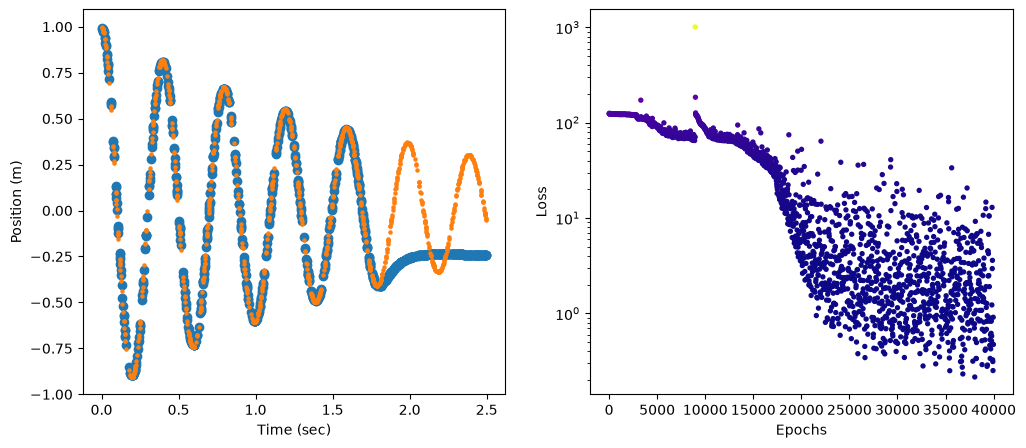

: 

In [ ]:
time = np.random.uniform(low=0.0, high=2.5, size=(1000,1))
time = np.sort(time)
real_sol = np.exp(-gamma*time)*np.cos(w_d*time)

time = torch.from_numpy(time).float().requires_grad_(True)
pos = net(time)

time = time.detach().numpy()
pos = pos.detach().cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 5)) 
ax1, ax2 = axes

ax1.scatter(x=time, y=pos)
ax1.set_xlabel("Time (sec)")  
ax1.set_ylabel("Position (m)")
ax1.scatter(time, real_sol, s=5)


epoch_list = list(range(0, len(loss_pts)*20, 20))
loss_pts[0] = loss_pts[1]

scatter = ax2.scatter(x=epoch_list, y=loss_pts, c=loss_pts, cmap='plasma', s=8)
ax2.set_xlabel("Epochs")  
ax2.set_ylabel("Loss") 
ax2.set_yscale('log') 
plt.show()